# MLP surrogate for the Hannover beam FEM

Train a PyTorch network to predict the **six FEM natural frequencies** from added mass and position. The labels are synthetic FEM results, not experimental measurements. The dataset reserves entire positions for validation and testing; the 120 cm position is evaluated separately as an edge case.

Install the repository's `requirements-ml.txt` in a Python environment and open this notebook with that kernel. The current Docker image is for FEM validation and does not include PyTorch.

In [1]:
from pathlib import Path
from hashlib import sha256
from copy import deepcopy
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'data/generated/fem_dataset.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the structural-surrogate-modeling project')
CSV = ROOT / 'data/generated/fem_dataset.csv'
metadata = json.loads(CSV.with_suffix('.json').read_text())
assert sha256(CSV.read_bytes()).hexdigest() == metadata['csv_sha256']
assert metadata['dataset_type'] == 'synthetic_fem'
assert not metadata['experimental_data_included']
df = pd.read_csv(CSV)
features = metadata['input_columns']
targets = metadata['target_columns']
split_names = ('train', 'val', 'test', 'test_edge')
assert set(df['split']) == set(split_names)
for a in split_names:
    for b in split_names:
        if a < b:
            assert set(df.loc[df.split == a, 'position_cm']).isdisjoint(
                set(df.loc[df.split == b, 'position_cm']))
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__, '| cases:', len(df))
print(df.groupby('split', sort=False).size().to_string())
display(df.head(3))

Python: 3.10.18
PyTorch: 2.2.2 | cases: 1176
split
train        966
val          105
test          84
test_edge     21


,position_cm,node,mass_g,split,f1_hz,f2_hz,f3_hz,f4_hz,f5_hz,f6_hz
0,10,10,1.0,train,3.572157,13.837891,33.574628,64.321809,105.132436,157.895787
1,10,10,2.5,train,3.572159,13.837888,33.574596,64.321612,105.131637,157.893438
2,10,10,5.0,train,3.572158,13.837884,33.574542,64.321285,105.130306,157.889521


## Inputs, targets, and baseline

The MLP receives `position_cm` and `mass_g` and predicts `f1_hz` to `f6_hz`. Means and standard deviations come **only from training rows**. This gives each input and each mode a comparable numerical scale without using information from validation or test rows. A linear regression fitted to the same training rows provides a simple baseline.

In [2]:
x = df[features].to_numpy(dtype=np.float32)
y = df[targets].to_numpy(dtype=np.float32)
splits = df['split'].to_numpy()
masks = {name: splits == name for name in split_names}

x_mean, x_std = x[masks['train']].mean(0), x[masks['train']].std(0)
y_mean, y_std = y[masks['train']].mean(0), y[masks['train']].std(0)
assert np.all(x_std > 0) and np.all(y_std > 0)
x_scaled = (x - x_mean) / x_std
y_scaled = (y - y_mean) / y_std

linear_design = np.column_stack((np.ones(masks['train'].sum()), x_scaled[masks['train']]))
linear_coef = np.linalg.lstsq(linear_design, y_scaled[masks['train']], rcond=None)[0]
def predict_linear(name):
    design = np.column_stack((np.ones(masks[name].sum()), x_scaled[masks[name]]))
    return (design @ linear_coef) * y_std + y_mean

reference_hz = np.asarray(metadata['reference_frequencies_hz'])
print('Training input mean:', dict(zip(features, np.round(x_mean, 3))))
print('Training input std:', dict(zip(features, np.round(x_std, 3))))

Training input mean: {'position_cm': 62.826, 'mass_g': 25.048}
Training input std: {'position_cm': 32.655, 'mass_g': 15.061}


## Train the MLP

Architecture: **2 inputs → 32 tanh → 32 tanh → 6 outputs**. The loss is mean squared error on standardized frequencies. Adam updates the weights; the validation loss selects the best epoch. Test rows are not used for fitting or selection. A fixed seed makes reruns reproducible on this CPU setup.

Best epoch: 1479; stopped after 1500 epochs; validation MSE: 0.000792308


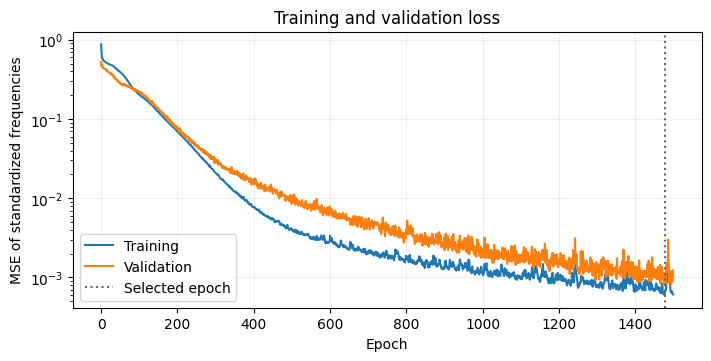

In [3]:
torch.set_num_threads(2)
torch.manual_seed(42)
np.random.seed(42)
model = nn.Sequential(
    nn.Linear(2, 32), nn.Tanh(),
    nn.Linear(32, 32), nn.Tanh(),
    nn.Linear(32, 6),
)
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
train_loader = DataLoader(
    TensorDataset(torch.from_numpy(x_scaled[masks['train']]),
                  torch.from_numpy(y_scaled[masks['train']])),
    batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(42),
)
x_val = torch.from_numpy(x_scaled[masks['val']])
y_val = torch.from_numpy(y_scaled[masks['val']])

history = {'train': [], 'val': []}
best_loss, best_epoch, best_state = float('inf'), 0, None
max_epochs, patience = 1500, 120
for epoch in range(1, max_epochs + 1):
    model.train()
    train_sum = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = nn.functional.mse_loss(model(xb), yb)
        loss.backward()
        optimizer.step()
        train_sum += loss.item() * len(xb)
    train_loss = train_sum / masks['train'].sum()
    model.eval()
    with torch.no_grad():
        val_loss = nn.functional.mse_loss(model(x_val), y_val).item()
    history['train'].append(train_loss)
    history['val'].append(val_loss)
    if val_loss < best_loss - 1e-6:
        best_loss, best_epoch = val_loss, epoch
        best_state = deepcopy(model.state_dict())
    if epoch - best_epoch >= patience:
        break
model.load_state_dict(best_state)
model.eval()
print(f'Best epoch: {best_epoch}; stopped after {epoch} epochs; validation MSE: {best_loss:.6g}')

fig, ax = plt.subplots(figsize=(7, 3.5), layout='constrained')
ax.plot(history['train'], label='Training')
ax.plot(history['val'], label='Validation')
ax.axvline(best_epoch - 1, color='0.4', ls=':', label='Selected epoch')
ax.set(xlabel='Epoch', ylabel='MSE of standardized frequencies', yscale='log',
       title='Training and validation loss')
ax.grid(alpha=.2)
ax.legend()
plt.show()

## Error on unseen positions

For each mode, **MAE (Hz)** is the mean absolute difference between MLP prediction and FEM label. The table also expresses test MAE as a percentage of that mode's FEM reference frequency. These errors measure how well the MLP approximates the FEM; they do **not** measure agreement with experiments.

,mode,test_MLP_MAE_Hz,test_MLP_MAE_pct_of_reference,test_linear_MAE_Hz,edge_MLP_MAE_Hz,edge_linear_MAE_Hz
0,1,0.0009,0.0250,0.0336,0.0126,0.1144
1,2,0.0022,0.0159,0.0925,0.0679,0.4410
2,3,0.0062,0.0184,0.2609,0.1843,0.9785
3,4,0.0203,0.0315,0.5815,0.3494,1.4024
4,5,0.0356,0.0338,0.8677,0.6032,1.6146
5,6,0.0668,0.0423,0.6613,1.1626,1.9793


Mean over six modes — test: 0.0220 Hz; 120 cm edge: 0.3967 Hz


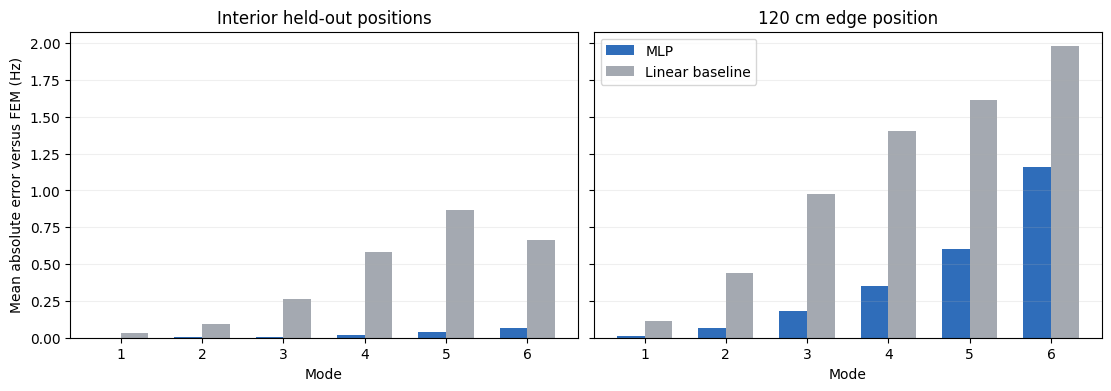

In [4]:
def predict_mlp(name):
    with torch.no_grad():
        scaled = model(torch.from_numpy(x_scaled[masks[name]])).numpy()
    return scaled * y_std + y_mean

predictions = {name: predict_mlp(name) for name in split_names}
mae = {name: np.mean(np.abs(predictions[name] - y[masks[name]]), axis=0)
       for name in split_names}
linear_mae = {name: np.mean(np.abs(predict_linear(name) - y[masks[name]]), axis=0)
              for name in ('test', 'test_edge')}
metrics = pd.DataFrame({
    'mode': np.arange(1, 7),
    'test_MLP_MAE_Hz': mae['test'],
    'test_MLP_MAE_pct_of_reference': 100 * mae['test'] / reference_hz,
    'test_linear_MAE_Hz': linear_mae['test'],
    'edge_MLP_MAE_Hz': mae['test_edge'],
    'edge_linear_MAE_Hz': linear_mae['test_edge'],
})
display(metrics.round(4))
print(f"Mean over six modes — test: {mae['test'].mean():.4f} Hz; "
      f"120 cm edge: {mae['test_edge'].mean():.4f} Hz")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained', sharey=True)
for ax, name, title in zip(axes, ('test', 'test_edge'),
                           ('Interior held-out positions', '120 cm edge position')):
    modes = np.arange(1, 7)
    ax.bar(modes - .17, mae[name], width=.34, label='MLP', color='#2f6dba')
    ax.bar(modes + .17, linear_mae[name], width=.34, label='Linear baseline', color='#a4a9b1')
    ax.set(xlabel='Mode', xticks=modes, title=title)
    ax.grid(axis='y', alpha=.2)
axes[0].set_ylabel('Mean absolute error versus FEM (Hz)')
axes[1].legend()
plt.show()

## Relative frequency shifts in the measured modes

The prior validation notebook compared experiments with FEM modes 2–4. Here the same modes are plotted as **percentage shifts from the FEM reference**. Each point compares an MLP prediction with its FEM label for a held-out case. The diagonal represents perfect FEM emulation; the measured frequencies are not used in this plot.

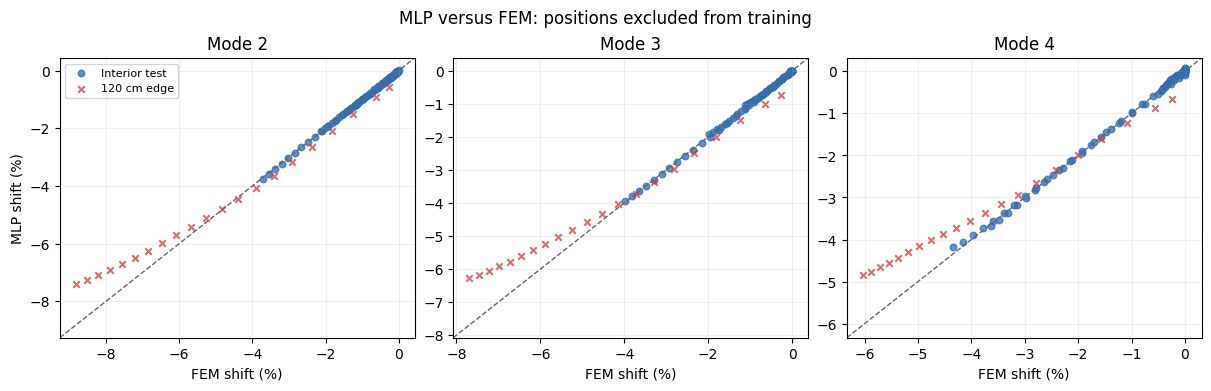

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout='constrained')
for ax, mode in zip(axes, (2, 3, 4)):
    j = mode - 1
    for name, color, marker, label in (
        ('test', '#2f6dba', 'o', 'Interior test'),
        ('test_edge', '#c93f40', 'x', '120 cm edge')):
        true_shift = 100 * (y[masks[name], j] / reference_hz[j] - 1)
        pred_shift = 100 * (predictions[name][:, j] / reference_hz[j] - 1)
        ax.scatter(true_shift, pred_shift, s=22, alpha=.75,
                   color=color, marker=marker, label=label)
    limits = np.array([*ax.get_xlim(), *ax.get_ylim()])
    low, high = limits.min(), limits.max()
    ax.plot([low, high], [low, high], '--', lw=1, color='0.4')
    ax.set(xlim=(low, high), ylim=(low, high),
           xlabel='FEM shift (%)', ylabel='MLP shift (%)' if mode == 2 else '',
           title=f'Mode {mode}')
    ax.grid(alpha=.2)
axes[0].legend(loc='upper left', fontsize=8)
fig.suptitle('MLP versus FEM: positions excluded from training')
plt.show()

## Save and interpret

The trained weights and training-only scaling constants are saved locally under `results/` (ignored by Git). The model performs much better on held-out interior positions than at 120 cm, where it has to extend beyond the largest training position (118 cm). This is an initial architecture, not a claim that the FEM or MLP matches the physical beam. Experimental evaluation remains a separate next step.

In [6]:
model_path = ROOT / 'results/mlp_fem_model.pt'
model_path.parent.mkdir(exist_ok=True)
torch.save({
    'state_dict': model.state_dict(),
    'x_mean': torch.from_numpy(x_mean.copy()),
    'x_std': torch.from_numpy(x_std.copy()),
    'y_mean': torch.from_numpy(y_mean.copy()),
    'y_std': torch.from_numpy(y_std.copy()),
    'features': features,
    'targets': targets,
    'dataset_sha256': metadata['csv_sha256'],
    'best_epoch': best_epoch,
}, model_path)
check = torch.load(model_path, map_location='cpu', weights_only=True)
assert check['dataset_sha256'] == metadata['csv_sha256']
print('Saved model:', model_path.relative_to(ROOT), f'({model_path.stat().st_size / 1024:.1f} KiB)')

Saved model: results/mlp_fem_model.pt (9.1 KiB)


## What happens relative to experiments?

The MLP was trained on FEM outputs. The Hannover measurements let us separate two discrepancies for the **same 34 added-mass configurations and modes 2–4**. Each measured configuration contributes one mean of its paired relative-frequency shifts, as in `hannover_validacion_fem.ipynb`. The metric is **mean absolute error of frequency shift in percentage points (pp)**, so the three comparisons share the same units and cases.

For each case and mode, signed errors satisfy

$$e_{\mathrm{MLP-exp}} = e_{\mathrm{MLP-FEM}} + e_{\mathrm{FEM-exp}}.$$

The **MAEs do not add**: opposite signed errors can partly cancel. No experimental observation was used to train or select the MLP. This section runs when the official Hannover MAT files are present locally; otherwise it reports that the comparison was skipped.

,mode,MLP–FEM MAE (pp),FEM–experiment MAE (pp),MLP–experiment MAE (pp)
0,2,0.095,0.093,0.153
1,3,0.105,0.217,0.306
2,4,0.101,0.256,0.324


Configurations: 34 | each measured configuration has equal weight


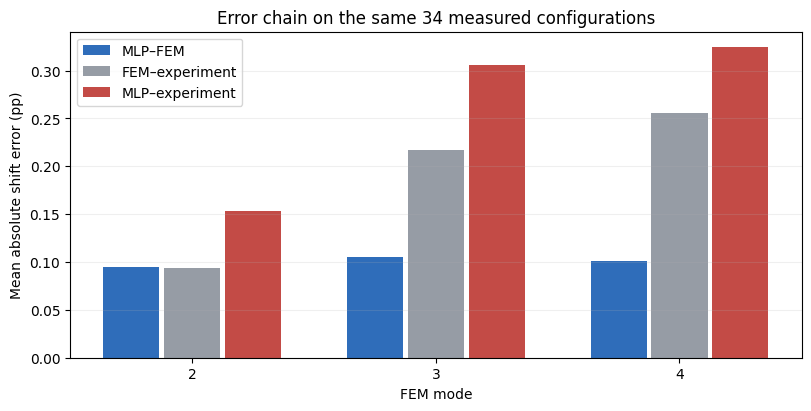

In [7]:
from scipy.io import loadmat

beam_path = ROOT / 'data/extracted/Code_Veröffentlichung/Data/BeamData/LiveBeamData.mat'
modal_path = ROOT / 'data/extracted/Code_Veröffentlichung/Data/ModalProperties/LiveBeamModalData.mat'
if not (beam_path.is_file() and modal_path.is_file()):
    print('Experimental comparison skipped: run setup_hannover.sh to obtain the official MAT files.')
else:
    sys.path.insert(0, str(ROOT / 'src'))
    from mass_changes import MassChanges

    fem_model = MassChanges.from_mat(beam_path)
    modal = loadmat(modal_path)
    cases = modal['mfMassCase']
    added_cases = np.unique(cases[cases[:, 1] > 0], axis=0)
    assert len(added_cases) == 34
    fem_ref = fem_model.frequencies()[1:4]
    fem_hz = np.array([fem_model.frequencies(int(node), grams / 1000)[1:4]
                       for node, grams in added_cases])
    measured_shift = np.array([
        (100 * (modal['mfFreqAna'][np.all(cases == case, axis=1)] /
                modal['mfFreqRef'][np.all(cases == case, axis=1)] - 1)).mean(axis=0)
        for case in added_cases])

    case_inputs = added_cases.astype(np.float32)
    with torch.no_grad():
        mlp_hz = (model(torch.from_numpy((case_inputs - x_mean) / x_std)).numpy()
                  * y_std + y_mean)[:, 1:4]
    fem_shift = 100 * (fem_hz / fem_ref - 1)
    mlp_shift = 100 * (mlp_hz / fem_ref - 1)
    signed_errors = {
        'MLP–FEM': mlp_shift - fem_shift,
        'FEM–experiment': fem_shift - measured_shift,
        'MLP–experiment': mlp_shift - measured_shift,
    }
    assert np.allclose(signed_errors['MLP–experiment'],
                       signed_errors['MLP–FEM'] + signed_errors['FEM–experiment'])
    shift_mae = pd.DataFrame({'mode': [2, 3, 4], **{
        f'{name} MAE (pp)': np.abs(error).mean(axis=0)
        for name, error in signed_errors.items()}})
    display(shift_mae.round(3))
    print('Configurations:', len(added_cases), '| each measured configuration has equal weight')

    fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
    modes = np.array([2, 3, 4])
    for offset, (name, error), color in zip(
        (-.25, 0, .25), signed_errors.items(), ('#2f6dba', '#969ca5', '#c34b46')):
        ax.bar(modes + offset, np.abs(error).mean(axis=0), width=.23,
               label=name, color=color)
    ax.set(xlabel='FEM mode', ylabel='Mean absolute shift error (pp)',
           title='Error chain on the same 34 measured configurations', xticks=modes)
    ax.grid(axis='y', alpha=.2)
    ax.legend()
    plt.show()

**Interpretation.** The MLP closely follows the FEM at interior positions, but its additional error is material in the experimental comparison because the 120 cm cases are outside the training position range. The FEM-to-experiment discrepancy persists even with a more accurate surrogate. These results quantify the present trained MLP only; they do not correct the FEM or establish physical accuracy at unmeasured configurations.